# BÁO CÁO TOÀN DIỆN: CHIẾN LƯỢC KHỞI TẠO TRỌNG SỐ (WEIGHT INITIALIZATION) TRONG MẠNG NƠ-RON SÂU

## 1. Bản chất và Mục tiêu của Khởi tạo trọng số
Trong một mạng nơ-ron nhiều lớp (MLP), dữ liệu truyền qua mỗi nơ-ron tuân theo hai bước tính toán cốt lõi:
1. **Phép biến đổi tuyến tính:** $$z = \sum_{i=1}^{n_{in}} w_i x_i + b$$
2. **Phép kích hoạt phi tuyến:** $$a = f(z)$$

**Khởi tạo trọng số (Weight Initialization)** là bước thiết lập các giá trị ban đầu cho ma trận trọng số $W$ trước khi thuật toán tối ưu bắt đầu quá trình huấn luyện. Một chiến lược khởi tạo đúng đắn phải tạo ra một vạch xuất phát hoàn hảo nhằm giải quyết hai bài toán sống còn:
*   **Phá vỡ tính đối xứng (Symmetry Breaking):** Đảm bảo các nơ-ron khởi đầu ở các trạng thái khác nhau để chúng học được các đặc trưng độc lập.
*   **Bảo toàn năng lượng tín hiệu (Signal Energy Preservation):** Giữ cho "âm lượng" của dữ liệu đi tới (Forward Pass) và đạo hàm truyền ngược (Backward Pass) ổn định qua hàng chục lớp ẩn.

---


## 3. Lý thuyết nền tảng và Minh họa bằng số học
Từ phương trình chứng minh trên, toàn bộ hệ thống đứng vững trên 2 điểm tựa toán học: Giá trị trung bình bằng $0$ và Phương sai phải được bảo toàn.

### 3.1. Tại sao luôn ép Giá trị trung bình bằng 0 ($\mathbb{E}[X] = 0$)?
*   **Ngăn chặn sự trôi dạt tín hiệu (Bias Shift):** Nếu trung bình của tín hiệu khác $0$, mạng nơ-ron sẽ liên tục cộng dồn một lượng sai số hệ thống sau mỗi lớp. Tín hiệu sẽ nhanh chóng trôi dạt ra xa khỏi gốc tọa độ về phía âm hoặc dương vô cực.
*   **Tránh vùng bão hòa (Saturation Avoidance):** Các hàm kích hoạt phi tuyến như Tanh hay Sigmoid có miền đồ thị nằm ngang ở hai đầu biên. Tại các vùng này, đạo hàm xấp xỉ bằng $0$. Nếu tín hiệu bị trôi dạt ra khỏi tâm $0$, các nơ-ron sẽ rơi vào trạng thái bão hòa, mất khả năng truyền đạo hàm ngược và ngừng học hoàn toàn.
*   **Ví dụ Minh họa:** 
    *   *Hoạt động tốt:* Tín hiệu $[-2, 4, -4, 2]$ có trung bình bằng $0$. Dữ liệu dao động đều quanh gốc tọa độ, duy trì tính đối xứng.
    *   *Hệ thống sụp đổ:* Tín hiệu $[0, 6, -2, 4]$ có trung bình là $2$. Đi qua các phép nhân dồn, phần dư dương này bị khuếch đại. Sau 10 lớp, dải tín hiệu trôi dạt thành $[1000, 1006, 998, 1004]$, rơi thẳng vào "vùng chết".

### 3.2. Tại sao phải bảo toàn Phương sai ($\text{Var}(z) = \text{Var}(x)$)?
Trong thống kê, khi trung bình bằng $0$, phương sai chính là **"Năng lượng" (Energy)** hoặc **"Độ tương phản"** của dữ liệu. 
Để tìm ra công thức khởi tạo chuẩn mực, ta cần giải bài toán: *Làm thế nào để năng lượng (phương sai) đầu ra bằng đúng năng lượng đầu vào?*

*   **Bước 1: Thiết lập phương trình phương sai**
    Từ phương trình tính đầu ra của một nơ-ron $z = \sum_{i=1}^{n_{in}} w_i x_i$, ta lấy phương sai hai vế. 
    Giả định các biến độc lập và hệ thống đã được ép kỳ vọng $\mathbb{E}[W] = \mathbb{E}[X] = 0$, phương sai của tổng sẽ bằng tổng các phương sai của tích:
    $$\text{Var}(z) = \sum_{i=1}^{n_{in}} \text{Var}(w_i) \cdot \text{Var}(x_i)$$

*   **Bước 2: Gom nhóm tham số**
    Do tất cả các trọng số $w$ và đầu vào $x$ đều được sinh ra từ cùng một phân phối (dùng chung một phương sai tổng thể), phép cộng $n_{in}$ lần được rút gọn thành phép nhân:
    $$\text{Var}(z) = n_{in} \cdot \text{Var}(W) \cdot \text{Var}(X)$$

*   **Bước 3: Giải phương trình bảo toàn năng lượng**
    Để dòng chảy tín hiệu không bị biến dạng, năng lượng đầu ra phải bằng năng lượng đầu vào ($\text{Var}(z) = \text{Var}(X)$). Ta ép phương trình trên về trạng thái cân bằng:
    $$\text{Var}(X) = n_{in} \cdot \text{Var}(W) \cdot \text{Var}(X)$$
    biểu thức $n_{in} \cdot \text{Var}(W)$ chính là **Hệ số khuếch đại tích lũy**. Nếu không ép hệ số này bằng $1$, mạng đối mặt rủi ro:
*   **Exploding Gradient (Bùng nổ đạo hàm):** Hệ số $> 1$, năng lượng tăng theo hàm mũ. Dữ liệu nhiễu loạn cực độ, gây tràn bộ nhớ (lỗi NaN).
*   **Vanishing Gradient (Triệt tiêu đạo hàm):** Hệ số $< 1$, năng lượng suy giảm theo hàm mũ về $0$. Thông tin mất đi "độ tương phản" thành một màu xám xịt.
*   **Ví dụ Minh họa (Mạng 10 lớp, $n_{in} = 100$):**
    *   *Bùng nổ:* Chọn $\text{Var}(W) = 0.02$, hệ số là $2.0$. Qua 10 lớp, năng lượng từ $1$ phóng to thành $1024$.
    *   *Triệt tiêu:* Chọn $\text{Var}(W) = 0.005$, hệ số là $0.5$. Qua 10 lớp, năng lượng teo tóp thành $0.0009$.
    *   *Bảo toàn hoàn hảo:* Chọn $\text{Var}(W) = 0.01$, hệ số là $1.0$. Qua 10 lớp, năng lượng giữ nguyên là $1.0$.

---

## 4. Phân tích chi tiết 4 Chiến lược Khởi tạo trọng số

### 4.1. Zero Initialization (Khởi tạo bằng 0)
*   **Cách thức:** Gán toàn bộ ma trận trọng số $W = 0$.
*   **Hàm kích hoạt tương thích:** **Không có.**
*   **Tại sao thất bại?** Gặp lỗi Symmetry (Tính đối xứng). Khi $W = 0$, mọi nơ-ron nhận cùng một dữ liệu, xuất ra cùng một kết quả, và nhận chung một giá trị đạo hàm truyền ngược. Toàn bộ các nơ-ron cập nhật giống hệt nhau, khiến mạng sâu trở nên vô dụng.


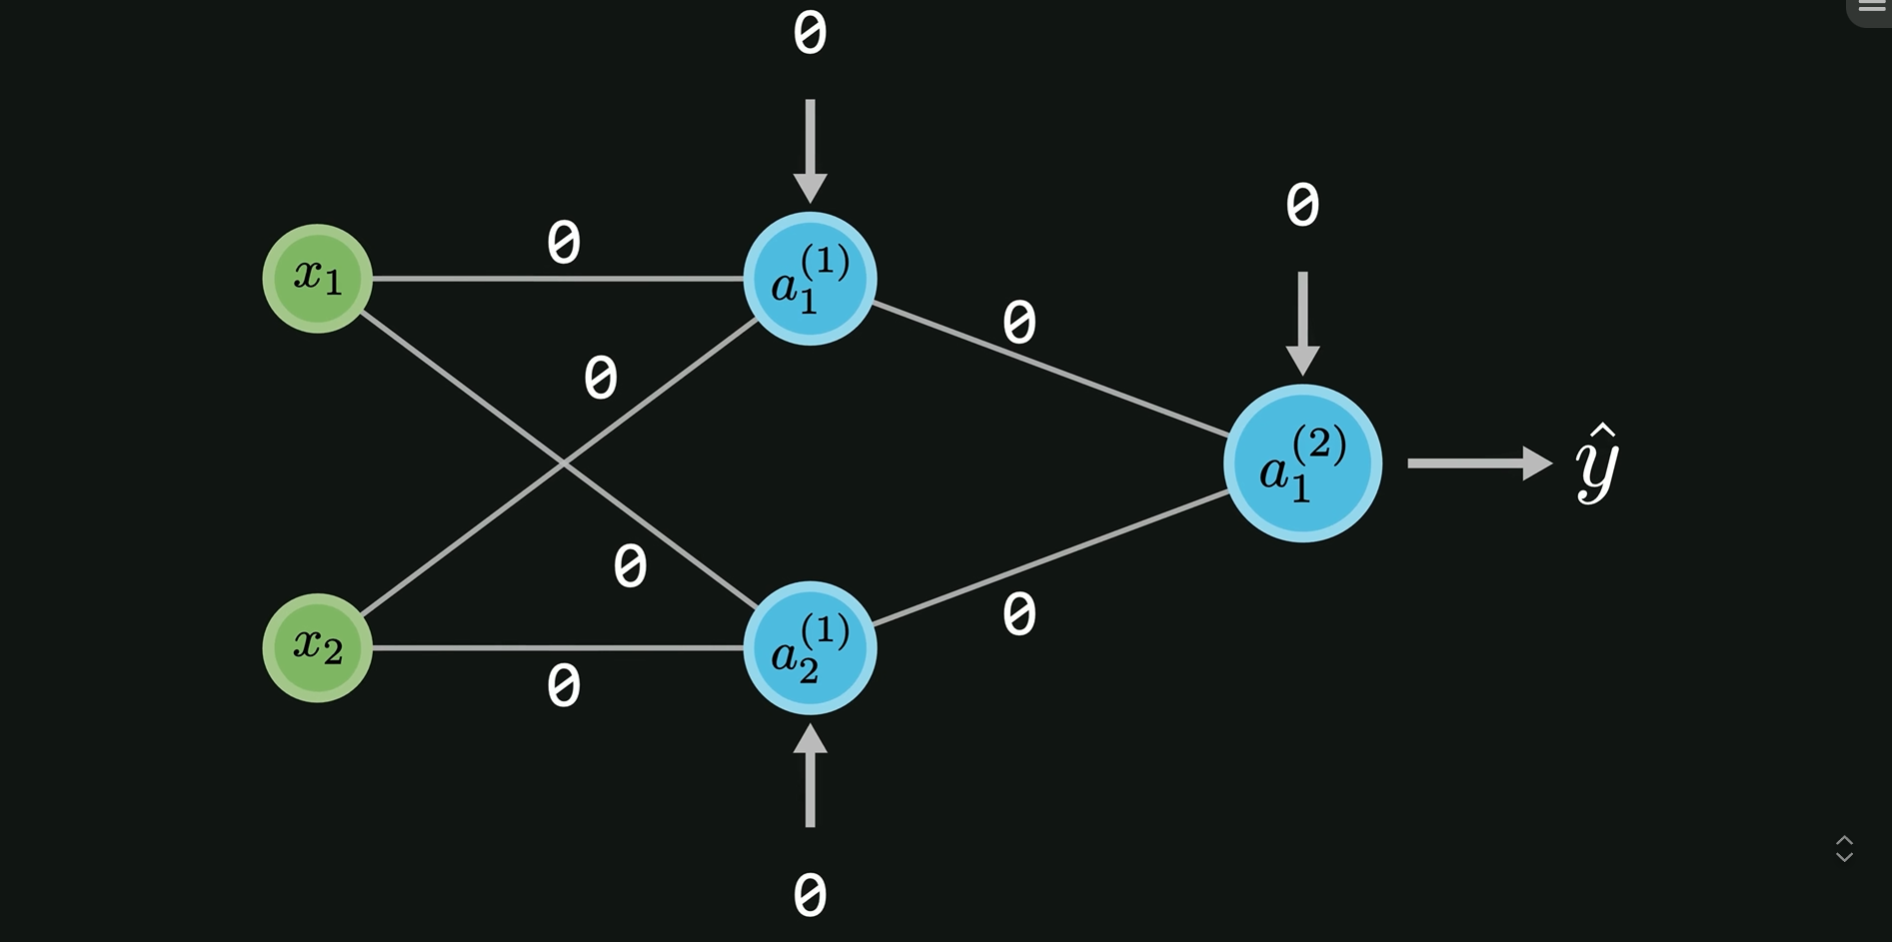
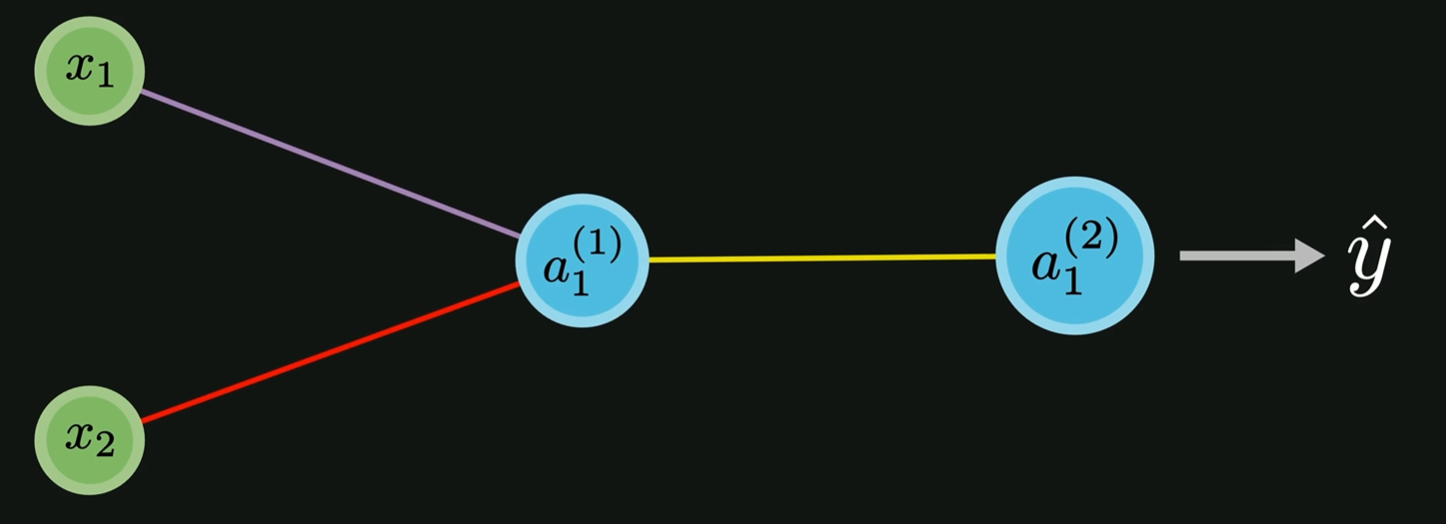


### 4.2. Random Initialization (Khởi tạo ngẫu nhiên cơ bản)
*   **Cách thức:** Lấy mẫu từ phân phối chuẩn với trung bình $\mu = 0$ và độ lệch chuẩn $\sigma$ cố định (ví dụ $0.01$).
*   **Hàm kích hoạt tương thích:** **Chỉ giới hạn ở mạng cực kỳ nông (1-2 lớp)**.
*   **Tại sao thất bại ở mạng sâu?** Thuật toán này phớt lờ yếu tố $n_{in}$. Hệ số khuếch đại $n_{in} \cdot \sigma^2$ sẽ gây bùng nổ đạo hàm nếu lớp có nhiều nơ-ron, hoặc gây triệt tiêu đạo hàm nếu chọn $\sigma$ quá nhỏ.

### 4.3. Xavier / Glorot Initialization (2010)

Mục tiêu của Xavier Glorot là tìm ra một mức phương sai khởi tạo $\text{Var}(W)$ sao cho "năng lượng" của luồng tín hiệu được bảo toàn nguyên vẹn ở cả hai chiều tiến và lùi.

*   **Chiều đi tới (Forward Pass):** 
    Tiếp nối phương trình bảo toàn năng lượng ở Mục 2: $\text{Var}(X) = n_{in} \cdot \text{Var}(W) \cdot \text{Var}(X)$. 
    Triệt tiêu $\text{Var}(X)$ ở cả hai vế, ta tìm ra được nghiệm duy nhất quy định độ lớn của trọng số, để tín hiệu đi từ lớp trước ra lớp sau không bị bùng nổ hay triệt tiêu (hệ số khuếch đại tạo bởi $n_{in}$ phải bằng $1$):
    $$n_{in} \cdot \text{Var}(W) = 1 \implies \mathbf{\text{Var}(W) = \frac{1}{n_{in}}}$$

*   **Chiều truyền ngược (Backward Pass):** 
    Khi lan truyền ngược, luồng đạo hàm (gradient) đi qua ma trận trọng số chuyển vị $W^T$, tức là nó phụ thuộc vào số lượng nơ-ron đầu ra ($n_{out}$). Để đạo hàm truyền về an toàn, hệ số khuếch đại chiều ngược cũng phải bằng $1$:
    $$n_{out} \cdot \text{Var}(W) = 1 \implies \mathbf{\text{Var}(W) = \frac{1}{n_{out}}}$$

*   **Sự thỏa hiệp (Glorot Compromise):** 
    Trong thực tế, $n_{in} \neq n_{out}$. Ta không thể thỏa mãn cùng lúc hai điều kiện trên. Để chia đều rủi ro cho cả hai chiều, Xavier đã quyết định lấy Trung bình điều hòa của hai phương sai lý tưởng này:
    $$\mathbf{\text{Var}(W) = \frac{2}{n_{in} + n_{out}}}$$

*   **Hàm kích hoạt phù hợp:** **Tanh, Softmax.**
*   **Tại sao phù hợp?** Hàm **Tanh** có đồ thị là một đường thẳng ($f(z) \approx z$) tại lân cận tâm $0$. Nhờ phương sai khởi tạo siêu nhỏ của Xavier, tín hiệu $z$ đi qua vùng tuyến tính này một cách mượt mà, giúp năng lượng được bảo toàn trọn vẹn $100\%$.


### Điểm mù toán học khi kết hợp với ReLU
Hàm kích hoạt ReLU được định nghĩa là $f(x) = \max(0, x)$. Về mặt bản chất, nó hoạt động như một bộ lọc phi tuyến, triệt tiêu hoàn toàn (đưa về $0$) tất cả các giá trị đầu vào mang dấu âm. 

Khi áp dụng Khởi tạo Xavier cho mạng sử dụng ReLU, nền tảng toán học bị phá vỡ vì hai hệ quả sau:
*   **Suy hao phương sai:** Vì ReLU cắt bỏ phân nửa phân phối dữ liệu (giả định dữ liệu phân phối chuẩn có tâm tại $0$), phương sai của các giá trị kích hoạt bị **giảm đi chính xác một nửa (50%)** sau khi đi qua mỗi lớp truyền tiến (Forward pass).
*   **Triệt tiêu Gradient (Vanishing Gradients):** Việc thất thoát $50\%$ phương sai qua mỗi lớp gây ra hiệu ứng domino. Trong các mạng nơ-ron sâu (Deep Neural Networks) có hàng chục lớp, phương sai của tín hiệu sẽ phân rã về $0$ theo cấp số nhân. Trong quá trình lan truyền ngược (Backward pass), gradient cũng bị triệt tiêu tương tự. Lỗi không thể truyền ngược về các lớp đầu tiên, khiến các lớp này gần như đóng băng (không được cập nhật tham số).

### 4.4. Kaiming / He Initialization
*   **Cách thức:** Lấy mẫu ngẫu nhiên từ phân phối có phương sai nhân đôi so với tiêu chuẩn:
    $$\text{Var}(W) = \frac{2}{n_{in}}$$
*   **Hàm kích hoạt phù hợp:** **Họ ReLU (ReLU, Leaky ReLU, PReLU).**
*   **Tại sao phù hợp?**
    Hàm **ReLU ($f(x) = \max(0, x)$)** cắt bỏ hoàn toàn các giá trị âm, chém đứt chính xác **$50\%$ phương sai (năng lượng)** của luồng dữ liệu. Nếu áp dụng Xavier cho ReLU, phương sai sẽ bị chia đôi sau mỗi lớp và dần triệt tiêu.
    Để giải quyết, Kaiming He **nhân đôi phương sai khởi tạo** (thêm số $2$ ở tử số). Việc bơm lượng tín hiệu mạnh gấp đôi ở vạch xuất phát đã bù trừ hoàn hảo cho việc hao hụt $50\%$ năng lượng khi đi qua "bộ lọc" ReLU, thiết lập tiêu chuẩn SOTA cho các kiến trúc học sâu hiện đại.

## Bản chất của Optimizer
Trong mạng nơ-ron, Optimizer (Bộ tối ưu hóa) đóng vai trò là cơ chế cốt lõi để cập nhật và tinh chỉnh các tham số (bao gồm ma trận trọng số $W$ và vector độ lệch $b$) trên không gian hàm mất mát (Loss landscape) nhằm tiến tới các điểm cực tiểu (minima).
Quá trình này được dẫn hướng bởi vector gradient ($dW, db$), đại diện cho chiều dốc nhất để cực tiểu hóa sai số. Tuy nhiên, việc tối ưu hóa thuần túy dựa trên gradient nguyên thủy thường không đạt hiệu suất cao. Các thuật toán tối ưu hóa hiện đại được phát triển nhằm khắc phục những hạn chế về tốc độ hội tụ, kiểm soát dao động và nâng cao khả năng tổng quát hóa (generalization) của mô hình.

---

## 1. SGD (Stochastic Gradient Descent)

SGD là thuật toán cơ sở, đóng vai trò nền tảng cho các phương pháp tối ưu hóa hiện đại. Việc cập nhật tham số được thực hiện trực tiếp dựa trên gradient tức thời tính toán từ các mini-batch.

### Cơ chế & Toán học
$$W := W - \alpha \cdot dW$$
$$b := b - \alpha \cdot db$$
*(Trong đó: $W$ là trọng số, $b$ là độ lệch, $\alpha$ là tốc độ học - Learning Rate, $dW$ và $db$ là đạo hàm tại bước hiện tại).*

### Phân tích Đặc tính
*   **Điểm mạnh:** Việc tính toán trên các mini-batch đưa vào quá trình tối ưu một lượng nhiễu ngẫu nhiên (stochastic noise). Tính ngẫu nhiên này tạo ra các dao động nội tại, giúp mô hình có khả năng thoát khỏi các điểm cực tiểu cục bộ hẹp (sharp minima) để hội tụ về các vùng cực tiểu phẳng (flat minima), qua đó cải thiện đáng kể khả năng tổng quát hóa của mạng.
*   **Điểm yếu (Giới hạn):** SGD cập nhật hoàn toàn phụ thuộc vào gradient tức thời. Trên các bề mặt Loss có độ cong không đồng đều (dạng thung lũng hẹp), thuật toán thường gặp phải hiện tượng dao động chéo (zigzag) dọc theo các trục có độ dốc lớn. Hậu quả là tốc độ hội tụ bị suy giảm nghiêm trọng.

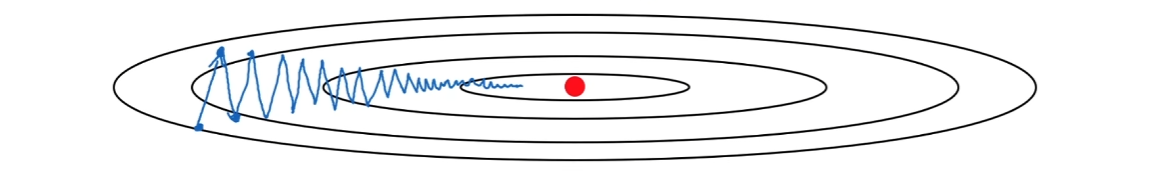

### Ứng Dụng
*   **Khi nào dùng:** Sử dụng trong giai đoạn tinh chỉnh (Fine-tuning) cuối cùng cho các mô hình đã được huấn luyện trước (Pre-trained models), hoặc trong các bài toán Machine Learning cơ bản.
*   **Tại sao:** Ở giai đoạn cuối của quá trình huấn luyện, khi mô hình đã tiến sát điểm cực tiểu, sự hội tụ chậm và các dao động ngẫu nhiên của SGD lại trở thành lợi thế. Chúng giúp mô hình tránh việc hội tụ quá sớm vào các cực tiểu hẹp và ổn định tại những vị trí có năng lực dự đoán thực tế cao nhất.
*   **Learning Rate tiêu chuẩn:** $0.1$ đến $0.01$.

---

## 2. SGD with Momentum

Để giải quyết hiện tượng dao động chéo và sự chậm chạp của SGD, thuật toán Momentum được giới thiệu bằng cách tích hợp phương pháp **Trung bình động có trọng số mũ (Exponentially Weighted Moving Average - EWMA)**. Phương pháp này duy trì một thành phần động lượng, đóng vai trò lưu trữ lịch sử gradient của các bước cập nhật trước đó.

### Cơ chế & Toán học
$$V_{dW} = \beta \cdot V_{dW} + (1 - \beta) \cdot dW \quad ; \quad V_{db} = \beta \cdot V_{db} + (1 - \beta) \cdot db$$
$$W := W - \alpha \cdot V_{dW} \quad ; \quad b := b - \alpha \cdot V_{db}$$
*(Trong đó: $V$ là moment bậc một/động lượng tích lũy, $\beta$ là hệ số kiểm soát sự phân rã của động lượng).*

### Phân tích Đặc tính
Sự can thiệp của EWMA tạo ra hai tác động cơ học xuất sắc:
*   **Triệt tiêu dao động (Damping):** Tại các vùng không gian hẹp nơi gradient đổi dấu liên tục, phép cộng dồn trong phương trình EWMA giúp các thành phần đối nghịch tự trung hòa. Nhờ đó, các dao động trực giao (zigzag) bị triệt tiêu đáng kể.
*   **Gia tốc hội tụ (Acceleration):** Dọc theo các phương có hướng dốc nhất quán, gradient cùng dấu được tích lũy liên tục, tạo thành động lượng (Inertial Momentum) lớn. Điều này giúp mô hình duy trì tốc độ cập nhật cao khi đi qua các vùng bình nguyên (plateaus) có độ dốc thấp.
*   **Điểm yếu (Giới hạn):** Áp dụng một tốc độ học (Global LR) đồng nhất cho mọi tham số. Động lượng tích lũy quá lớn, nếu thiếu cơ chế điều tiết, có thể dẫn đến hiện tượng vượt lố (overshooting) khỏi điểm cực tiểu toàn cục.

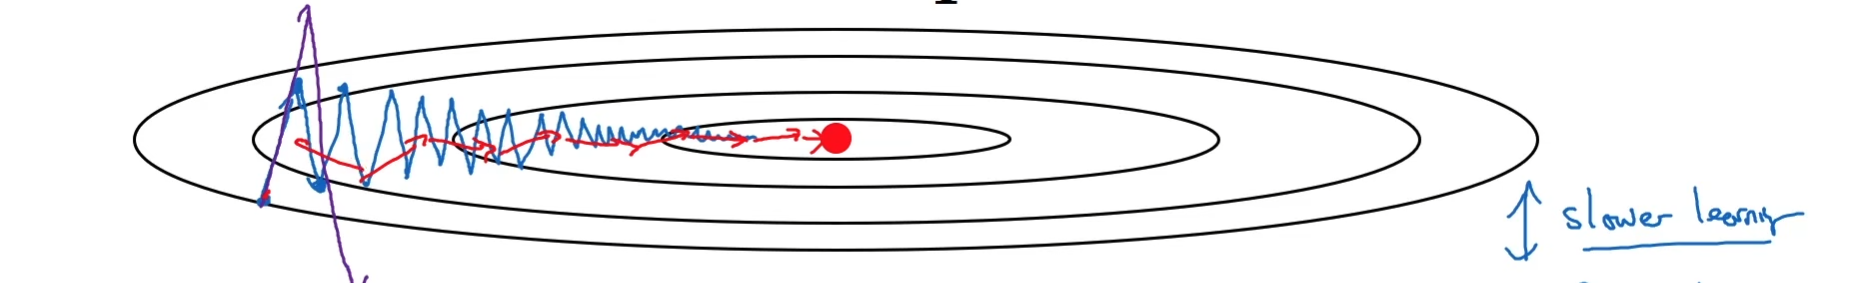

### Ứng Dụng
*   **Khi nào dùng:** Mặc định cho việc huấn luyện các kiến trúc Mạng nơ-ron tích chập (CNN) trong thị giác máy tính như ResNet, VGG.
*   **Tại sao:** Động lượng tích lũy thuần túy của Momentum có khả năng giúp mô hình vượt qua các vùng hội tụ cục bộ kém tối ưu. Dù yêu cầu quá trình tinh chỉnh (tuning) siêu tham số phức tạp hơn, các kiến trúc CNN được tối ưu bằng Momentum thường đạt hiệu suất phân loại (Accuracy) kiểm định cao hơn so với các phương pháp thích ứng.
*   **Learning Rate tiêu chuẩn:** $0.01$ (Luôn đi kèm hệ số động lượng $\beta = 0.9$).

---

## 3. RMSProp

Khác với phương pháp tích lũy động lượng, RMSProp tối ưu hóa quá trình huấn luyện thông qua cơ chế **Tốc độ học thích ứng (Adaptive Learning Rate)**. Thuật toán này điều chỉnh bước cập nhật (step size) độc lập cho từng chiều không gian của tham số.

### Cơ chế & Toán học
$$S_{dW} = \beta \cdot S_{dW} + (1 - \beta) \cdot dW^2 \quad ; \quad S_{db} = \beta \cdot S_{db} + (1 - \beta) \cdot db^2$$
$$W := W - \alpha \frac{dW}{\sqrt{S_{dW}} + \varepsilon} \quad ; \quad b := b - \alpha \frac{db}{\sqrt{S_{db}} + \varepsilon}$$
*(Trong đó: $S$ là moment bậc hai/phương sai đo lường độ phân tán của gradient, $\varepsilon$ là hằng số bảo vệ tránh lỗi chia cho $0$).*

### Phân tích Đặc tính
*   **Chuẩn hóa cục bộ (Local Scaling):**
    *   **Đối với các chiều có gradient biến thiên mạnh (Dao động lớn):** $S_{dW}$ sẽ tăng rất cao. Khi đem chia cho $\sqrt{S_{dW}}$ lớn, phân số sẽ bị thu hẹp lại, làm giảm bước cập nhật giúp quỹ đạo đi mượt mà hơn, tránh dao động zíc-zắc.
    *   **Đối với các chiều thưa thớt (Sparse features có gradient nhỏ):** $S_{dW}$ rất thấp. Khi chia cho một số $\sqrt{S_{dW}}$ nhỏ xíu, nó sẽ khuếch đại tín hiệu cập nhật lên, giúp đẩy nhanh tốc độ học ở những vùng này và ngăn chặn tình trạng suy giảm gradient.

*   **Điểm yếu (Đình trệ - Stalling):**
    *   Vì RMSProp tính $S$ dựa trên trung bình trượt, khi mô hình đi vào các vùng bình nguyên phẳng phới (nơi gradient tức thời $dW \approx 0$), thành phần $S$ sẽ giảm dần về $0$. Điều này khiến mẫu số $\sqrt{S}$ rất nhỏ, vô tình làm cho bước cập nhật bị đình trệ đáng kể ở giai đoạn cuối.
### Ứng Dụng
*   **Khi nào dùng:** Lựa chọn ưu tiên cho các Mạng nơ-ron hồi quy (RNNs, LSTMs, GRUs) trong xử lý chuỗi thời gian, hoặc các Hệ thống gợi ý (Recommender Systems).
*   **Tại sao:** Trong cấu trúc dữ liệu chuỗi, hiện tượng triệt tiêu hoặc bùng nổ gradient (vanishing/exploding gradients) diễn ra phổ biến. Cơ chế điều chuẩn dựa trên phương sai của RMSProp giúp bình ổn các đạo hàm này, đảm bảo tính hội tụ an toàn khi học các chuỗi dữ liệu dài.
*   **Learning Rate tiêu chuẩn:** $0.001$.

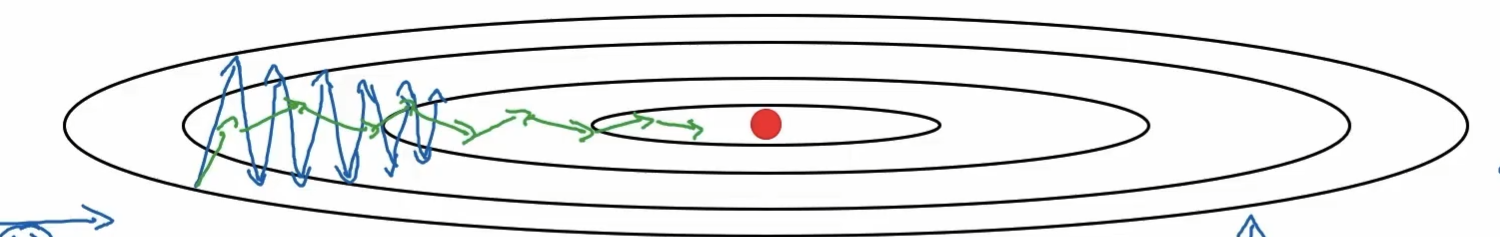

---

## 4. Adam (Adaptive Moment Estimation)

Adam (Adaptive Moment Estimation) được thiết kế nhằm giải quyết bài toán bù trừ: **Momentum có năng lực gia tốc nhưng thiếu cơ chế điều chuẩn cục bộ, trong khi RMSProp kiểm soát phương sai xuất sắc nhưng lại dễ bị đình trệ tại các vùng phẳng.** Adam dung hợp trực tiếp cả hai ưu điểm này.

### Cơ chế & Toán học
Thuật toán trải qua 4 bước tính toán trong mỗi vòng lặp $t$:

**Bước 1: Tính Moment bậc 1 (Động lượng - Kế thừa Momentum)**
$$V_{dW} = \beta_1 \cdot V_{dW} + (1 - \beta_1) \cdot dW \quad ; \quad V_{db} = \beta_1 \cdot V_{db} + (1 - \beta_1) \cdot db$$

**Bước 2: Tính Moment bậc 2 (Phương sai - Kế thừa RMSProp)**
$$S_{dW} = \beta_2 \cdot S_{dW} + (1 - \beta_2) \cdot dW^2 \quad ; \quad S_{db} = \beta_2 \cdot S_{db} + (1 - \beta_2) \cdot db^2$$

**Bước 3: Hiệu chỉnh chệch (Bias Correction)**
Do $V$ và $S$ được khởi tạo bằng $0$, tại các bước cập nhật đầu tiên, giá trị ước lượng bị chệch mạnh về $0$. Bước này nhằm loại bỏ độ chệch khởi tạo (Cold Start bias):
$$V_{dW}^{\text{corrected}} = \frac{V_{dW}}{1 - \beta_1^t} \quad ; \quad V_{db}^{\text{corrected}} = \frac{V_{db}}{1 - \beta_1^t}$$
$$S_{dW}^{\text{corrected}} = \frac{S_{dW}}{1 - \beta_2^t} \quad ; \quad S_{db}^{\text{corrected}} = \frac{S_{db}}{1 - \beta_2^t}$$

**Bước 4: Cập nhật tham số**
$$W := W - \alpha \frac{V_{dW}^{\text{corrected}}}{\sqrt{S_{dW}^{\text{corrected}}} + \varepsilon} \quad ; \quad b := b - \alpha \frac{V_{db}^{\text{corrected}}}{\sqrt{S_{db}^{\text{corrected}}} + \varepsilon}$$

### Phân tích Đặc tính
*   **Khả năng hội tụ toàn diện:** Adam duy trì được động lượng (tử số) để vượt qua các vùng gradient suy biến, đồng thời có khả năng điều chuẩn bước cập nhật riêng biệt (mẫu số) cho từng tham số, hạn chế tối đa hiện tượng vượt lố.
*   **Điểm yếu (Rủi ro Quá khớp - Overfitting):**
    1. Sự biến dạng của đạo hàm**
Khi áp dụng Chuẩn hóa L2 để phạt các trọng số $W$ quá lớn, một lượng phạt $\lambda W$ được cộng trực tiếp vào đạo hàm gốc:
$$dW_{\text{mới}} = dW_{\text{gốc}} + \lambda W$$

    2. Công thức cập nhật mắc lỗi**
Thuật toán Adam mang toàn bộ $dW_{\text{mới}}$ này đi tính toán và đưa vào phương trình cập nhật (chia cho căn bậc hai của phương sai $S$). Phương trình lúc này trở thành:
$$W := W - \alpha \frac{dW_{\text{gốc}} + \lambda W}{\sqrt{S}}$$


*   **Với các tham số dao động mạnh (chứa nhiều nhiễu, dễ gây quá khớp):** Phương sai $S$ ở mẫu số sẽ tự động phình lên rất to.
*   **Hiệu ứng "Bão hòa phạt":** Khi lấy lượng phạt $\lambda W$ đem chia cho một mẫu số $\sqrt{S}$ khổng lồ, toàn bộ phân số $\frac{\lambda W}{\sqrt{S}}$ sẽ bị ép tiệm cận về $0$.
*   **Hậu quả:** Những trọng số phức tạp, bất trị lẽ ra cần bị phạt nặng nhất để giữ cho mô hình đơn giản thì nay lại gần như không bị phạt một chút nào. Mô hình bị mất kiểm soát độ phức tạp, tự do uốn cong để "học vẹt" các điểm nhiễu trong dữ liệu, dẫn đến tình trạng Overfitting.
### Ứng Dụng
*   **Khi nào dùng:** Trong các dự án yêu cầu xây dựng nguyên mẫu (Prototyping) nhanh, phân tích dữ liệu dạng bảng, hoặc huấn luyện các cấu trúc mạng không quá phức tạp.
*   **Tại sao:** Sự cố Quá khớp của Adam xuất phát từ một xung đột toán học khi nó kết hợp với kỹ thuật Chuẩn hóa L2 (L2 Regularization) để tính toán đạo hàm.

*   **Learning Rate tiêu chuẩn:** $0.001$ (kèm $\beta_1=0.9, \beta_2=0.999$).

---

## 5. AdamW (Adam with Decoupled Weight Decay)

Để khắc phục rủi ro quá khớp và sai lệch toán học trong Adam nguyên bản, AdamW ra đời với chiến lược **Phân tách (Decoupling)**. Sự cải tiến này là yếu tố cốt lõi giúp họ thuật toán Adam trở thành tiêu chuẩn cho hầu hết các mô hình quy mô lớn hiện hành.

### Cơ chế & Toán học
Thành phần chuẩn hóa L2 (Weight decay) được tách rời hoàn toàn khỏi quá trình tính toán moment bậc hai của Adam, và được áp dụng trực tiếp như một hàm suy giảm ở bước cuối cùng. *(Lưu ý: Đối với vector độ lệch $b$, do ít chịu rủi ro quá khớp nên chuẩn hóa Weight Decay thường bị lược bỏ).*

$$W := W - \alpha \left( \frac{V_{dW}^{\text{corrected}}}{\sqrt{S_{dW}^{\text{corrected}}} + \varepsilon} \right) - \alpha \lambda W$$
$$b := b - \alpha \left( \frac{V_{db}^{\text{corrected}}}{\sqrt{S_{db}^{\text{corrected}}} + \varepsilon} \right)$$
*(Trong đó: $\lambda$ là hệ số suy giảm trọng số - Weight Decay coefficient).*

### Phân tích Đặc tính
Thông qua việc áp dụng độc lập đại lượng phạt $\alpha \lambda W$, AdamW bảo toàn tính toàn vẹn toán học của cơ chế chuẩn hóa. Bất chấp sự biến thiên của gradient nội tại hay moment bậc hai, mọi trọng số đều được kiểm soát biên độ một cách nghiêm ngặt. Phương pháp này kết hợp thành công tốc độ hội tụ ưu việt của Adam với năng lực tổng quát hóa mạnh mẽ.

### Ứng Dụng
*   **Khi nào dùng:** Đóng vai trò là phương pháp **MẶC ĐỊNH cho hơn 90%** các tác vụ Deep Learning hiện đại, đặc biệt thiết yếu đối với các mô hình cấu trúc phức tạp và quy mô lớn (Large Language Models, Transformers, BERT, Vision Transformers).
*   **Tại sao:** AdamW mang đến sự cân bằng tối ưu: giữ được gia tốc tính toán vượt trội, giảm thiểu khối lượng công việc tinh chỉnh siêu tham số, đồng thời duy trì được hiệu suất dự đoán cực kỳ ổn định trên các tập dữ liệu ngoại lai (unseen data).
*   **Learning Rate tiêu chuẩn:** $10^{-3}$ đến $10^{-4}$ (Kết hợp với hệ số chuẩn hóa Weight Decay $\lambda = 0.01$).